In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

album = pd.read_csv("Album.csv")
artist= pd.read_csv("Artist.csv")
customer = pd.read_csv("Customer.csv")
employee = pd.read_csv("Employee.csv")
genre = pd.read_csv("Genre.csv")
invoice = pd.read_csv("Invoice.csv")
invoice_line = pd.read_csv("InvoiceLine.csv")
media = pd.read_csv("MediaType.csv")
playlist = pd.read_csv("Playlist.csv")
playlist_track = pd.read_csv("PlayListTrack.csv")
track = pd.read_csv("Track.csv")

## Ejercicio 1

<Axes: xlabel='count', ylabel='Country'>

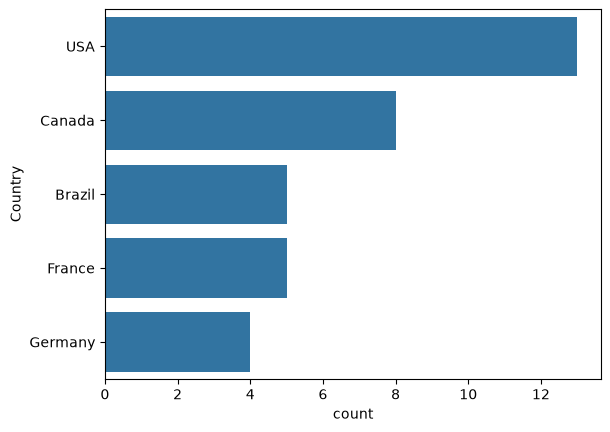

In [2]:
df_1= customer["Country"].value_counts().sort_values(ascending=False).head().index
sns.countplot(data=customer,y="Country", order=df_1)

In [3]:
invoice

,InvoiceId,CustomerId,InvoiceDate,BillingAddress,BillingCity,BillingState,BillingCountry,BillingPostalCode,Total
0,1,2,2021-01-01 00:00:00,Theodor-Heuss-Straße 34,Stuttgart,NaN,Germany,70174,1.98
1,2,4,2021-01-02 00:00:00,Ullevålsveien 14,Oslo,NaN,Norway,0171,3.96
2,3,8,2021-01-03 00:00:00,Grétrystraat 63,Brussels,NaN,Belgium,1000,5.94
3,4,14,2021-01-06 00:00:00,8210 111 ST NW,Edmonton,AB,Canada,T6G 2C7,8.91
4,5,23,2021-01-11 00:00:00,69 Salem Street,Boston,MA,USA,2113,13.86
...,...,...,...,...,...,...,...,...,...
407,408,25,2025-12-05 00:00:00,319 N. Frances Street,Madison,WI,USA,53703,3.96
408,409,29,2025-12-06 00:00:00,796 Dundas Street West,Toronto,ON,Canada,M6J 1V1,5.94
409,410,35,2025-12-09 00:00:00,"Rua dos Campeões Europeus de Viena, 4350",Porto,NaN,Portugal,NaN,8.91
410,411,44,2025-12-14 00:00:00,Porthaninkatu 9,Helsinki,NaN,Finland,00530,13.86


## Ejercicio 2

<Axes: xlabel='BillingCountry', ylabel='Total'>

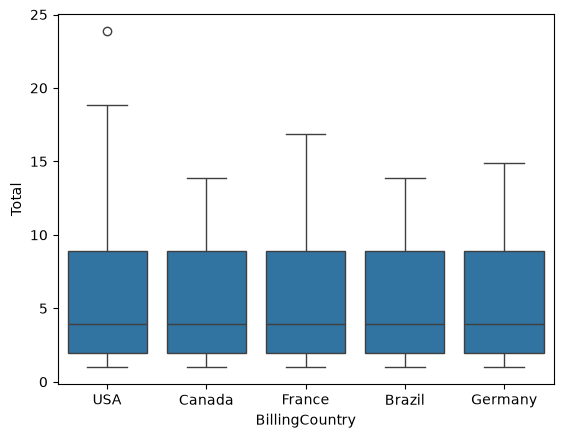

In [5]:
df_2=invoice["BillingCountry"].value_counts().sort_values(ascending=False).head().index
sns.boxplot(data=invoice, x="BillingCountry",y="Total",order=df_2)

## Ejercicio 3

<Axes: xlabel='SupportRepId', ylabel='Total'>

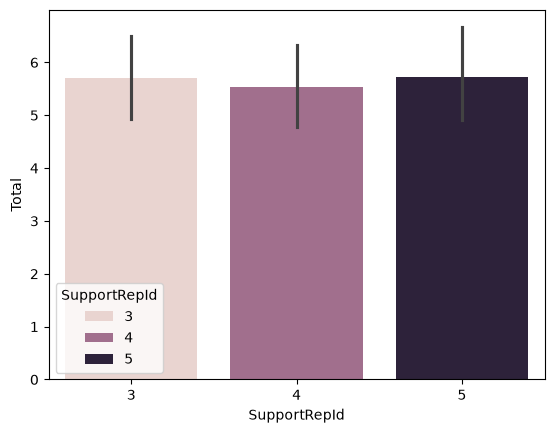

In [7]:
df_3= invoice.merge(customer, on="CustomerId", how="left")
df_3 = df_3.merge(employee, left_on="SupportRepId",right_on="EmployeeId",how="left")
sns.barplot(data=df_3, x="SupportRepId", y="Total",hue="SupportRepId")

## Ejercicio 4


Text(0.5, 1.0, 'Stripplot duración de Rock y Latin')

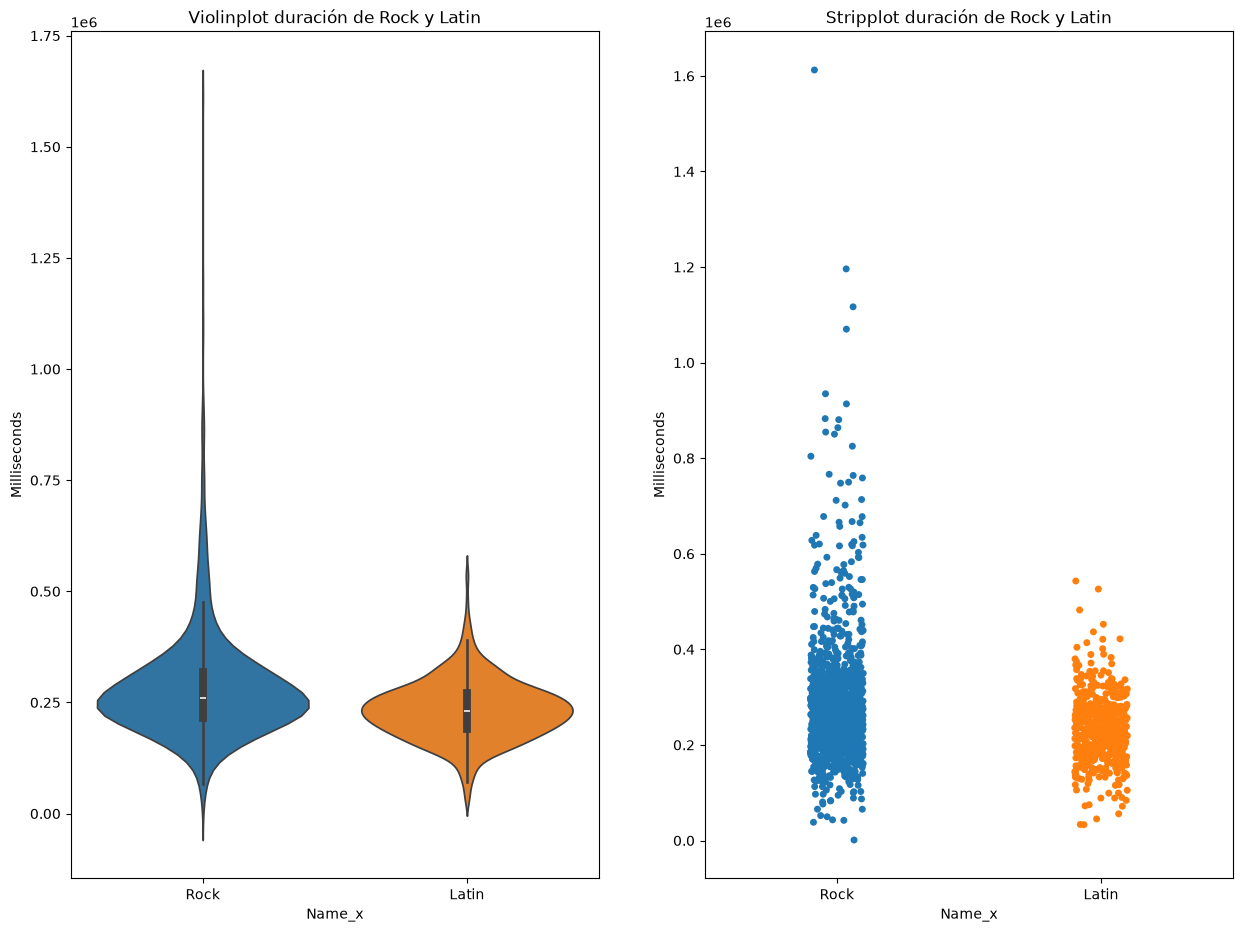

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(15, 11), squeeze = False)
df41 = genre.merge(track, on = "GenreId", how = "left")
df41 = df41[(df41["Name_x"] == "Rock") | (df41["Name_x"] == "Latin")]
sns.violinplot(data= df41, x="Name_x", y="Milliseconds", hue = "Name_x", ax= axes[0,0])
axes[0, 0].set_title("Violinplot duración de Rock y Latin")
sns.stripplot(data= df41, x="Name_x", y="Milliseconds", hue = "Name_x", ax= axes[0,1])
axes[0, 1].set_title("Stripplot duración de Rock y Latin")

## Ejercicio 5

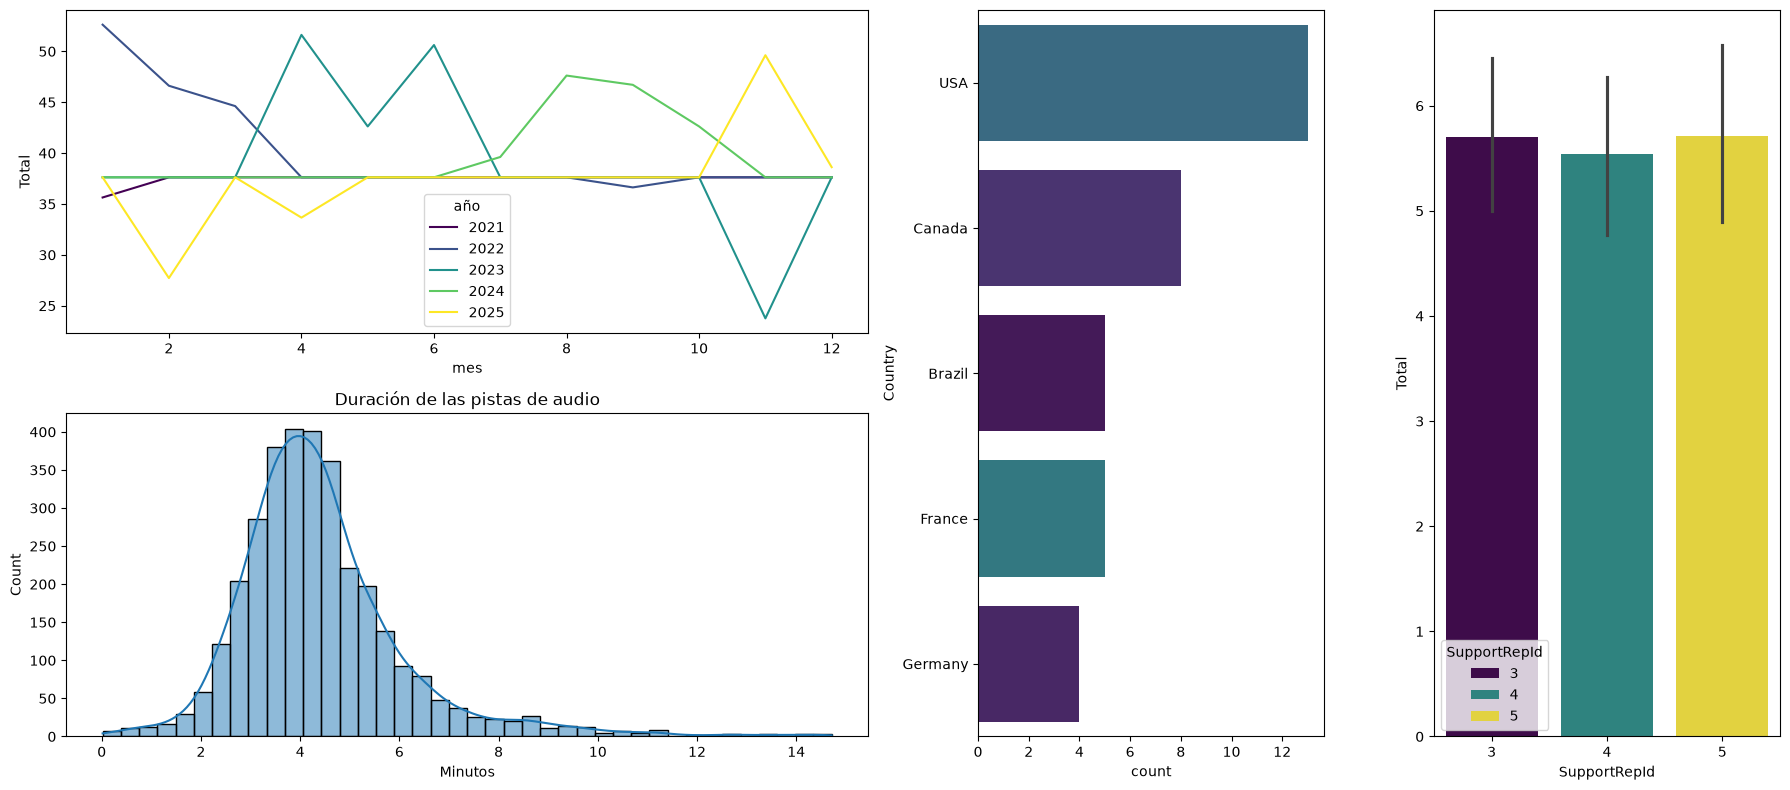

In [14]:
fig, axes = plt.subplot_mosaic("AABC;DDBC", figsize=(18, 8))

# Plot A
invoice["InvoiceDate"] = pd.to_datetime(
    invoice["InvoiceDate"],
    format="%Y-%m-%d %H:%M:%S",
    errors="coerce"
)
invoice["año"] = invoice["InvoiceDate"].dt.year
invoice["mes"] = invoice["InvoiceDate"].dt.month
mensual = invoice.groupby(["año", "mes"], as_index=False)["Total"].sum()
sns.lineplot(data=mensual, x="mes", y="Total", hue="año", palette="viridis", ax = axes["A"])

# Plot B
dfb = customer["Country"].value_counts().sort_values(ascending=False).head().index
sns.countplot(data = customer, y = "Country", order = dfb, hue = "Country", ax = axes["B"], palette="viridis")

# Plot C
df3 = invoice.merge(customer, on = "CustomerId", how = "left" )
df3 = df3.merge(employee, left_on = "SupportRepId", right_on = "EmployeeId", how = "left" )
sns.barplot(data = df3, x = "SupportRepId", y = "Total", hue= "SupportRepId", ax = axes["C"], palette="viridis")

# Plot D
pistas = (track
    .merge(genre.rename(columns={"Name": "Genero"}), on="GenreId")
    .merge(media.rename(columns={"Name": "Medio"}), on="MediaTypeId")
    .merge(album, on="AlbumId")
    .merge(artist.rename(columns={"Name": "Artista"}), on="ArtistId")
    .rename(columns={"Name": "Pista"}))
pistas["Minutos"] = pistas["Milliseconds"] / 60000
pistas["MB"] = pistas["Bytes"] / 1e6
audio = pistas[(pistas["Minutos"] < 15) & ~pistas["Medio"].str.contains("video")]
sns.histplot(data=audio, x="Minutos", bins=40, kde=True, ax = axes["D"])
plt.title("Duración de las pistas de audio")

plt.tight_layout()

## Ejercicio 6

Text(0.5, 1.0, 'Número de facturas por país y año')

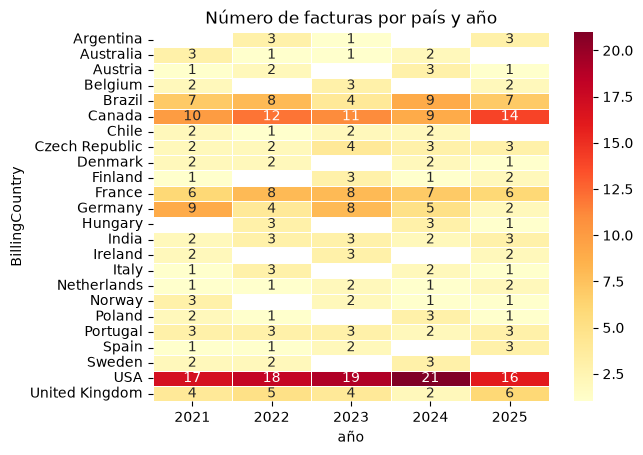

In [ ]:
invoice["InvoiceDate"] = pd.to_datetime(
    invoice["InvoiceDate"],
    format="%Y-%m-%d %H:%M:%S",
    errors="coerce"6y7aj9   
)

invoice["año"] = invoice["InvoiceDate"].dt.year
tabla = invoice.pivot_table(
    values = "InvoiceId", 
    index = "BillingCountry",
    aggfunc = "count",
    columns = "año"
)

sns.heatmap(tabla, annot=True, fmt=".0f", cmap="YlOrRd", linewidths=0.5)
plt.title("Número de facturas por país y año")